In [95]:
from nba_api.stats.endpoints import leaguedashteamstats
import pandas as pd
import time

seasons = [
    f"{year}-{str(year + 1)[-2:]}"
    for year in range(2000, 2025)
]

all_seasons = []

for season in seasons:
    
    print(f"Downloading {season}...")
    
    stats = leaguedashteamstats.LeagueDashTeamStats(
        season=season,
        season_type_all_star="Regular Season",
        per_mode_detailed="PerGame"
    )
    
    df = stats.get_data_frames()[0]
    
    # Keep the variables we need
    df = df[
        [
            "TEAM_NAME",
            "GP",
            "FGA",
            "FG3A",
            "FG3M",
            "FG3_PCT",
            "PTS",
            "W_PCT",
            "W",
            "L",    
            "OREB",
            "DREB",
            "AST",
            "TOV",
            "STL",
            "BLK"
        ]
    ].copy()
    
    # Add season
    df["SEASON"] = season
    
    # Store this season
    all_seasons.append(df)


In [96]:
for season in all_seasons:
    print(season.columns)
    print(season['TEAM_NAME'])

Index(['TEAM_NAME', 'GP', 'FGA', 'FG3A', 'FG3M', 'FG3_PCT', 'PTS', 'W_PCT',
       'W', 'L', 'OREB', 'DREB', 'AST', 'TOV', 'STL', 'BLK', 'SEASON'],
      dtype='str')
0              Atlanta Hawks
1             Boston Celtics
2          Charlotte Hornets
3              Chicago Bulls
4        Cleveland Cavaliers
5           Dallas Mavericks
6             Denver Nuggets
7            Detroit Pistons
8      Golden State Warriors
9            Houston Rockets
10            Indiana Pacers
11      Los Angeles Clippers
12        Los Angeles Lakers
13                Miami Heat
14           Milwaukee Bucks
15    Minnesota Timberwolves
16           New Jersey Nets
17           New York Knicks
18             Orlando Magic
19        Philadelphia 76ers
20              Phoenix Suns
21    Portland Trail Blazers
22          Sacramento Kings
23         San Antonio Spurs
24       Seattle SuperSonics
25           Toronto Raptors
26                 Utah Jazz
27       Vancouver Grizzlies
28        Washington 

In [35]:
avg_3pm = []
avg_3pa = []
avg_3pp = []
for season in all_seasons:
    avg_3pm.append(season['FG3M'].mean().round(2))
    avg_3pa.append(season['FG3A'].mean().round(2))
    avg_3pp.append(season['FG3_PCT'].mean().round(4))

print(avg_3pm)
print(avg_3pa)
print(avg_3pp)
   
    

[np.float64(4.84), np.float64(5.21), np.float64(5.13), np.float64(5.18), np.float64(5.6), np.float64(5.73), np.float64(6.07), np.float64(6.56), np.float64(6.65), np.float64(6.44), np.float64(6.46), np.float64(6.41), np.float64(7.16), np.float64(7.74), np.float64(7.85), np.float64(8.51), np.float64(9.65), np.float64(10.49), np.float64(11.36), np.float64(12.19), np.float64(12.71), np.float64(12.44), np.float64(12.34), np.float64(12.84), np.float64(13.54)]
[np.float64(13.71), np.float64(14.76), np.float64(14.68), np.float64(14.92), np.float64(15.75), np.float64(15.98), np.float64(16.94), np.float64(18.11), np.float64(18.13), np.float64(18.14), np.float64(18.01), np.float64(18.39), np.float64(19.97), np.float64(21.54), np.float64(22.41), np.float64(24.08), np.float64(27.0), np.float64(29.0), np.float64(32.01), np.float64(34.1), np.float64(34.64), np.float64(35.18), np.float64(34.21), np.float64(35.11), np.float64(37.58)]
[np.float64(0.3518), np.float64(0.3518), np.float64(0.3466), np.float

'\nprint(round(avg_3pm, 2))\nprint(round(avg_3pa, 2))\nprint(round(avg_3pp, 2))\n'

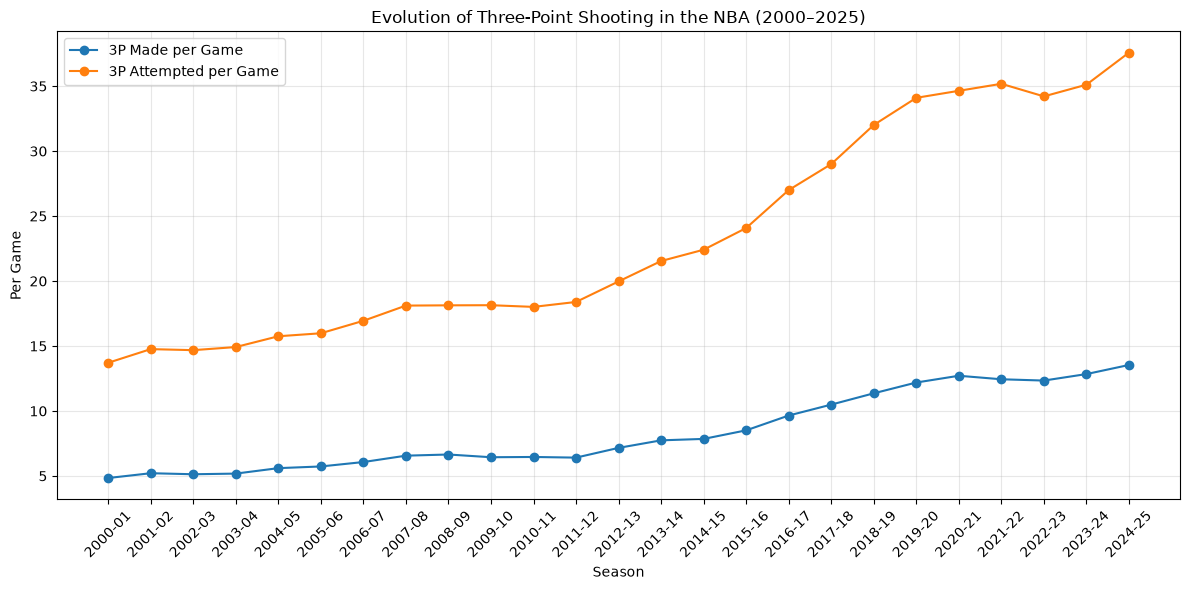

In [97]:
import matplotlib.pyplot as plt

seasons = [f"{year}-{str(year+1)[-2:]}" for year in range(2000, 2025)]

plt.figure(figsize=(12, 6))

plt.plot(seasons, avg_3pm, marker='o', label='3P Made per Game')
plt.plot(seasons, avg_3pa, marker='o', label='3P Attempted per Game')

plt.xlabel('Season')
plt.ylabel('Per Game')
plt.title('Evolution of Three-Point Shooting in the NBA (2000–2025)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

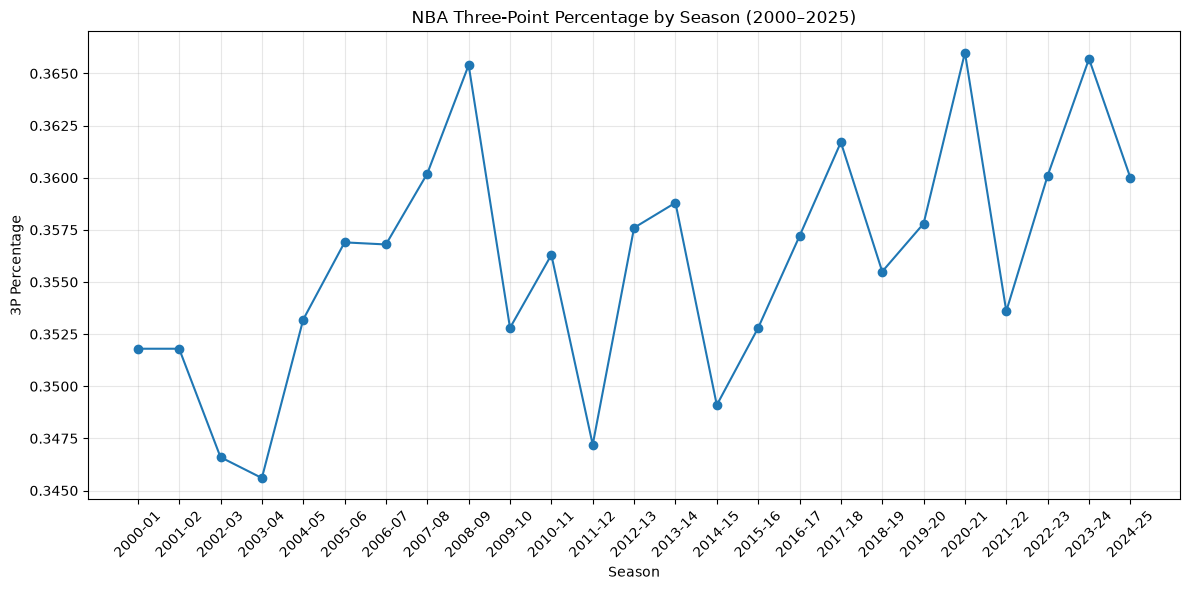

In [98]:
plt.figure(figsize=(12, 6))

plt.plot(seasons, avg_3pp, marker='o', label='3P%')

plt.xlabel('Season')
plt.ylabel('3P Percentage')
plt.title('NBA Three-Point Percentage by Season (2000–2025)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [99]:
#standardize the team names across 25 seasons 
all_team_names = set()

for season in all_seasons:
    all_team_names.update(season['TEAM_NAME'].dropna().unique())

sorted(all_team_names)


team_mapping = {
    'New Jersey Nets': 'Brooklyn Nets',
    'Charlotte Bobcats': 'Charlotte Hornets',
    'New Orleans Hornets': 'New Orleans Pelicans',
    'New Orleans Pelicans': 'New Orleans Pelicans',
    'New Orleans/Oklahoma City Hornets': 'New Orleans Pelicans',
    'Seattle SuperSonics': 'Oklahoma City Thunder',
    'Los Angeles Clippers': 'LA Clippers',
    'Vancouver Grizzlies': 'Memphis Grizzlies'
}

In [100]:
#mapping team names
for season in all_seasons:
    season['TEAM_NAME_STANDARD'] = season['TEAM_NAME'].replace(team_mapping)


In [112]:
seasons = [f"{year}-{str(year+1)[-2:]}" for year in range(2000, 2025)]

#prepare the ploting data for correlation between 3 point made and Win Percentage for each team. Only need team name, average 3 point made per season and win_percentage per season

plot_data = []

for i, season in enumerate(all_seasons):
    temp = season[['TEAM_NAME_STANDARD', 'FG3M', 'W_PCT']].copy()

    # Add the season label
    temp['Season'] = seasons[i]

    plot_data.append(temp)

plot_df = pd.concat(plot_data, ignore_index=True)

print(plot_df.shape)

(746, 4)


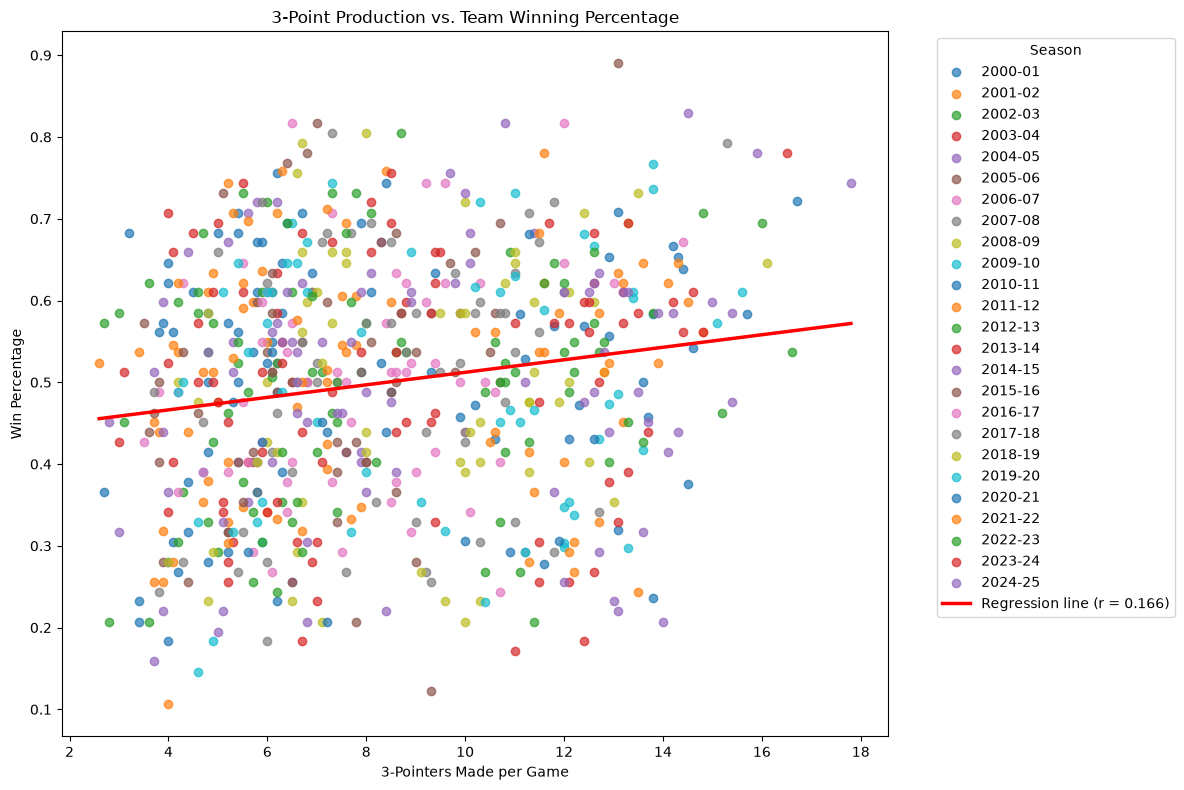

In [110]:
# Find the correlation between 3 point made vs win percentage for all teams
plt.figure(figsize=(12, 8))

for season_name, group in plot_df.groupby('Season'):
    plt.scatter(
        group['FG3M'],
        group['W_PCT'],
        label=season_name,
        alpha=0.7
    )

# Calculate the overall correlation and regression line
x = plot_df['FG3M']
y = plot_df['W_PCT']

slope, intercept = np.polyfit(x, y, 1)
correlation = x.corr(y)

# Draw the regression line
x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

plt.plot(
    x_line,
    y_line,
    color='red',
    linewidth=2.5,
    label=f'Regression line (r = {correlation:.3f})'
)

plt.xlabel('3-Pointers Made per Game')
plt.ylabel('Win Percentage')
plt.title('3-Point Production vs. Team Winning Percentage')
plt.legend(title='Season', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

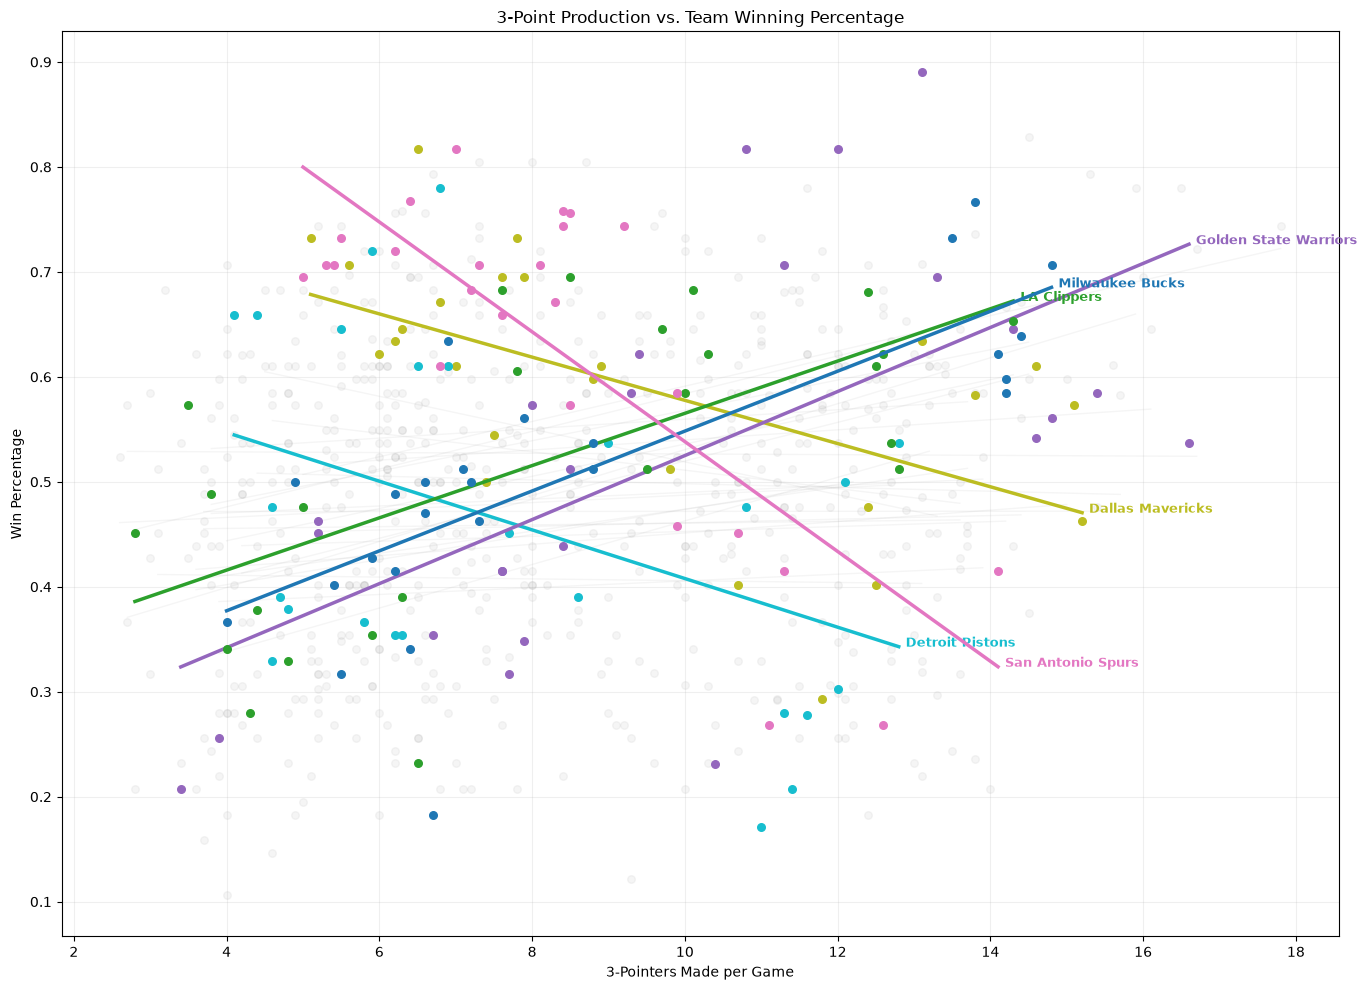

Top 3 positive correlations:
Milwaukee Bucks: r = 0.763
LA Clippers: r = 0.631
Golden State Warriors: r = 0.618

Top 3 negative correlations:
San Antonio Spurs: r = -0.784
Dallas Mavericks: r = -0.556
Detroit Pistons: r = -0.416


In [113]:
# Calculate correlation for each team
correlations = {}

for team, group in plot_df.groupby('TEAM_NAME_STANDARD'):
    if len(group) >= 2 and group['FG3M'].nunique() >= 2:
        correlations[team] = group['FG3M'].corr(group['W_PCT'])

# Identify top 3 positive and negative correlations
top_positive = sorted(correlations, key=correlations.get, reverse=True)[:3]
top_negative = sorted(correlations, key=correlations.get)[:3]

highlighted = top_positive + top_negative

# Assign a unique color to each highlighted team
colors = plt.cm.tab10(np.linspace(0, 1, 6))
team_colors = dict(zip(highlighted, colors))

plt.figure(figsize=(14, 10))

for team, group in plot_df.groupby('TEAM_NAME_STANDARD'):
    x = group['FG3M']
    y = group['W_PCT']

    is_highlighted = team in highlighted

    if is_highlighted:
        color = team_colors[team]
        alpha = 1
        linewidth = 2.5
        zorder = 3
    else:
        color = 'gray'
        alpha = 0.08
        linewidth = 1
        zorder = 1

    plt.scatter(x, y, color=color, alpha=alpha, s=30, zorder=zorder)

    if len(group) >= 2 and x.nunique() >= 2:
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        y_line = slope * x_line + intercept

        plt.plot(
            x_line, y_line,
            color=color,
            alpha=alpha,
            linewidth=linewidth,
            zorder=zorder
        )

        if is_highlighted:
            plt.annotate(
                team,
                (x_line[-1], y_line[-1]),
                xytext=(5, 0),
                textcoords='offset points',
                color=color,
                fontsize=9,
                fontweight='bold'
            )

plt.xlabel('3-Pointers Made per Game')
plt.ylabel('Win Percentage')
plt.title('3-Point Production vs. Team Winning Percentage')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Top 3 positive correlations:")
for team in top_positive:
    print(f"{team}: r = {correlations[team]:.3f}")

print("\nTop 3 negative correlations:")
for team in top_negative:
    print(f"{team}: r = {correlations[team]:.3f}")


In [106]:
columns = ["OREB", "DREB", "AST", "TOV", "STL", "BLK"]

season_correlations = []

for df in all_seasons:
    corr = df[columns].corrwith(df["W_PCT"])
    season_correlations.append(corr)

correlation_df = pd.DataFrame(season_correlations)

correlation_df["SEASON"] = seasons

print(correlation_df)

        OREB      DREB       AST       TOV       STL       BLK   SEASON
0  -0.251575  0.615429  0.328282 -0.620669  0.039693  0.291166  2000-01
1  -0.225156  0.543404  0.363059 -0.601346  0.309927  0.030516  2001-02
2  -0.281979  0.382800  0.415172 -0.522113  0.261882 -0.007136  2002-03
3  -0.132169  0.381785  0.577966 -0.492860  0.190529  0.346683  2003-04
4  -0.296981  0.626230  0.155056 -0.444128  0.053049  0.359946  2004-05
5  -0.165316  0.538964  0.417728 -0.575387 -0.171966  0.458904  2005-06
6  -0.155928  0.667323  0.404889 -0.547776 -0.051081  0.267358  2006-07
7  -0.094078  0.413283  0.487070 -0.472842  0.303990  0.312847  2007-08
8  -0.097139  0.567418  0.334845 -0.373767  0.208452  0.163405  2008-09
9  -0.206251  0.551551  0.396373 -0.429140 -0.033590  0.395870  2009-10
10 -0.475010  0.503240  0.319780 -0.484758  0.141743  0.024136  2010-11
11  0.010129  0.668440  0.317329 -0.170623  0.278338  0.256869  2011-12
12 -0.192203  0.392798  0.300157 -0.017778  0.565677  0.349894  

In [107]:
columns = ["OREB", "DREB", "AST", "TOV", "STL", "BLK"]

season_correlations = []

for df in all_seasons:
    corr = df[columns].corrwith(df["PTS"])
    season_correlations.append(corr)

correlation_df = pd.DataFrame(season_correlations)

correlation_df["SEASON"] = seasons

print(correlation_df)

        OREB      DREB       AST       TOV       STL       BLK   SEASON
0   0.200951  0.442065  0.438234 -0.384335  0.156168  0.456001  2000-01
1   0.016071  0.532530  0.469568 -0.498172  0.167827 -0.018592  2001-02
2  -0.010357  0.445837  0.517538 -0.366979  0.096917  0.170402  2002-03
3   0.204493  0.083418  0.637531 -0.473641  0.245753 -0.052385  2003-04
4  -0.011963  0.539593  0.215448 -0.348880  0.162059  0.080751  2004-05
5   0.048418  0.176818  0.446415 -0.189128  0.169203 -0.121492  2005-06
6  -0.156274  0.231154  0.647008 -0.021247  0.390960 -0.008421  2006-07
7  -0.121874  0.496848  0.616716  0.035828  0.460669  0.364228  2007-08
8   0.208000  0.437295  0.582038  0.230333  0.444511  0.236717  2008-09
9  -0.303655  0.333183  0.524157 -0.038579  0.141147 -0.064588  2009-10
10  0.042746  0.368426  0.355017  0.042124  0.219609  0.163026  2010-11
11  0.176877  0.433256  0.272049 -0.049690  0.337252  0.252204  2011-12
12 -0.269646  0.449798  0.406185  0.275369  0.523383  0.256138  

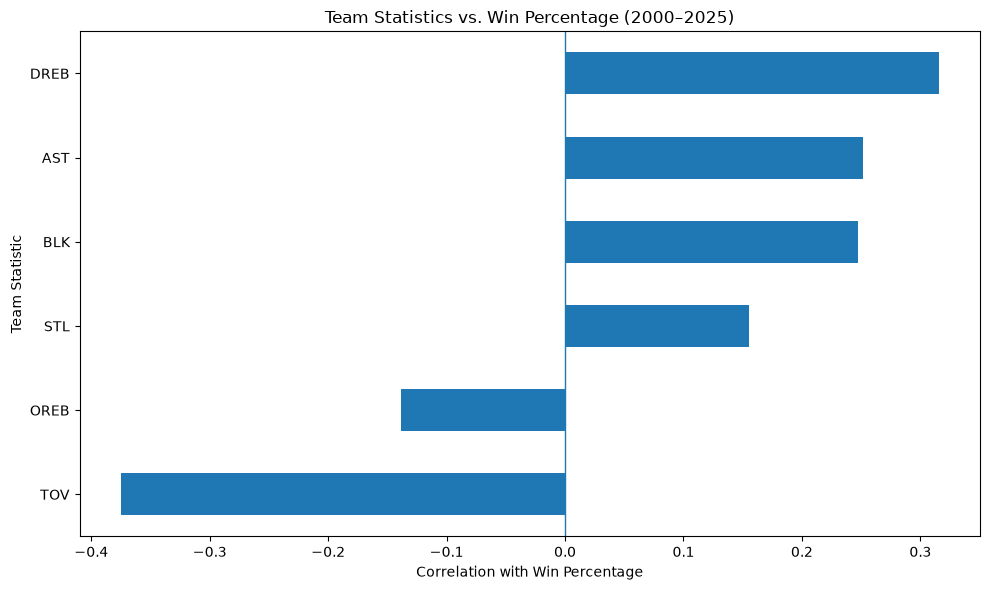

In [109]:
all_data = pd.concat(all_seasons, ignore_index=True)

columns = ["OREB", "DREB", "AST", "TOV", "STL", "BLK"]

correlation = (
    all_data[columns]
    .corrwith(all_data["W_PCT"])
    .sort_values()
)

plt.figure(figsize=(10, 6))

correlation.plot(kind="barh")

plt.axvline(0, linewidth=1)

plt.xlabel("Correlation with Win Percentage")
plt.ylabel("Team Statistic")
plt.title("Team Statistics vs. Win Percentage (2000–2025)")

plt.tight_layout()
plt.show()